# Modelagem Preditiva — Detecção de Fraude em Cartão de Crédito

Este notebook consome a Master Table gerada no notebook de Análise Exploratória e Engenharia de Recursos (`01_EDA.ipynb`) e desenvolve os modelos preditivos para estimativa da probabilidade de fraude em transações financeiras (`isFraud`).

## Estrutura da Esteira Preditiva:
1. **Configuração Inicial e Carregamento de Dados:** Imports, setup de caminhos, split temporal estrito em **3 blocos** (**60% Treino / 20% Validação (`df_validacao`) / 20% OOT**) e engenharia de features livre de leakage.
2. **Baselines de Modelos (Cross-Validation):** Avaliação comparativa com `GroupKFold` (CV=3) no Treino (`Treino` vs `Teste` no CV) e avaliação no bloco isolado de **Validação (`df_validacao`)**.
3. **Otimização Bayesiana de Hiperparâmetros (Optuna):** Busca focada no ROC-AUC via `GroupKFold` exclusivamente no Treino (60%).
4. **Hiperparâmetros Campeões (Hardcoded):** Versionamento estático e reprodutível das parametrizações ótimas.
5. **Avaliação dos Modelos Otimizados (Treino + Teste CV + Validação):** Validação cruzada no Treino e avaliação no conjunto de **Validação (`df_validacao`)**, mantendo o OOT cego.
   - *5.1 Ensemble:* [Placeholder em branco para modelagem e análise pós-primeira rodada].
6. **Calibração e Análise de Threshold:** [Placeholder em branco para varredura e calibração manual de ponto de corte].
7. **Análise de Importância Global e Poda Dimensional (SHAP):** Diagnóstico de impacto preditivo via TreeExplainer e sanity check de poda em **Validação (`df_validacao`)**.
8. **Avaliação Final no OOT e Exportação de Artefatos:** Prova final cega na base `df_oot` (últimos 20%) via `avaliar_classificacao_oot` e serialização do modelo campeão.


---
## 1.0 Configuração do Ambiente e Carregamento de Dados

- Inicialização das bibliotecas científicas e de machine learning.
- Importação das funções analíticas especializadas de `utils.py`.
- Definição das flags de execução e carregamento das bases particionadas.

> **Instalação de Pacotes (se necessário):**
> Caso alguma biblioteca não esteja instalada no seu ambiente atual, execute no terminal ou em uma célula do notebook:
> `!pip install -q lightgbm xgboost catboost optuna shap`


In [1]:
# ==============================================================================
# 1.0 CONFIGURAÇÃO DO AMBIENTE E IMPORTS
# ==============================================================================
import os
import sys
import json
import warnings
import importlib
from pathlib import Path

# Supressão de warnings para visualização limpa
warnings.filterwarnings('ignore')

# ------------------------------------------------------------------------------
# 1.1 Resolução Robusta da Raiz do Projeto (Local e Colab)
# ------------------------------------------------------------------------------
current_dir = Path(os.getcwd()).resolve()
if (current_dir / 'utils.py').exists():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / 'utils.py').exists():
    PROJECT_ROOT = current_dir.parent
elif (current_dir.parent.parent / 'utils.py').exists():
    PROJECT_ROOT = current_dir.parent.parent
else:
    PROJECT_ROOT = current_dir

os.chdir(PROJECT_ROOT)
for p in [str(PROJECT_ROOT), os.path.abspath('.'), os.path.abspath('..')]:
    if p not in sys.path:
        sys.path.append(p)

print(f"Diretório raiz configurado: {PROJECT_ROOT}")

# ------------------------------------------------------------------------------
# 1.2 Bibliotecas Científicas e de Machine Learning
# ------------------------------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import optuna
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

from sklearn.isotonic import IsotonicRegression
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler

# ------------------------------------------------------------------------------
# 1.3 Funções Especializadas de utils.py
# ------------------------------------------------------------------------------
import utils
importlib.reload(utils)

from utils import (
    preparar_dados_modelagem,
    avaliar_classificador,
    avaliar_classificacao_oot,
    plot_feature_importance,
    objective_lgbm,
    objective_xgb,
    objective_cat,
    obter_menores_features,
    podar_features_por_shap,
    exportar_artefatos_modelo,
)

print("Bibliotecas e módulos de utils.py importados com sucesso!")


Diretório raiz configurado: /content
Bibliotecas e módulos de utils.py importados com sucesso!


### 1.1 Flags de Execução

| Flag | Valor Padrão (`False`) | Modo Completo (`True`) | Justificativa Operacional |
|---|---|---|---|
| `RUN_OPTUNA` | Utiliza hiperparâmetros campeões hardcoded (Seção 4.0) | Executa 15 trials bayesianos por algoritmo | Economiza tempo computacional na rodada inicial |
| `RUN_SHAP_PRUNING` | Utiliza lista de poda estática (Seção 7.4) | Calcula SHAP values via TreeExplainer e avalia versão LITE | Permite teste rápido de poda sem recálculo pesado |


In [2]:
# ==============================================================================
# 1.1 FLAGS DE EXECUÇÃO — controle de processamento pesado
# ==============================================================================
RUN_OPTUNA       = False # Seção 3.0: 
RUN_SHAP_PRUNING = True    # Seção 7.2/7.3:


### 1.2 Carregamento da Master Table e Metadados

Carregamento do `df_master.parquet` e do arquivo `features_metadata.json` gerados na etapa de pré-processamento e seleção multivariada.


In [3]:
# ==============================================================================
# 1.2 CARREGAMENTO DA MASTER TABLE E METADADOS
# ==============================================================================
output_dir = PROJECT_ROOT / 'data' / 'processed'
parquet_path = output_dir / 'df_master.parquet'
meta_path = output_dir / 'features_metadata.json'

# Verificação de existência dos dados pré-processados
if not parquet_path.exists() or not meta_path.exists():
    raise FileNotFoundError(
        f"Arquivos não encontrados em {output_dir}!\n"
        "Certifique-se de executar o notebook 01_EDA.ipynb até o final para gerar "
        "df_master.parquet e features_metadata.json."
    )

# 1. Leitura do arquivo Parquet e metadados
df_master = pd.read_parquet(parquet_path)

with open(meta_path, 'r', encoding='utf-8') as f:
    meta = json.load(f)

print(f"Master Table carregada com sucesso. Shape inicial: {df_master.shape}")


Master Table carregada com sucesso. Shape inicial: (590540, 156)


### 1.3 Divisão Temporal Estrita (Treino 60% / Validação 20% / OOT 20%) e Engenharia Pós-Split

Para garantir **zero leakage**, a divisão dos dados é estritamente cronológica com base no tempo (`TransactionDT`):
- **Treino (`df_treino` — 60% iniciais):** Período histórico usado para `GroupKFold` por mês (`Treino` e `Teste` do CV) e tuning no Optuna.
- **Validação (`df_validacao` — 20% seguintes):** Base intermediária isolada para comparar Baselines, Otimizados, Threshold e Poda SHAP sem encostar no OOT.
- **Out-of-Time (`df_oot` — 20% finais):** Período futuro mantido **completamente cego e isolado** até a avaliação final na Seção 8.0.

Agregações históricas, frequency encoding e ordinal encoding são ajustados **exclusivamente no Treino (`df_treino`)** e aplicados por `.map()`/`.transform()` em `df_validacao` e `df_oot`.

In [ ]:
# ==============================================================================
# 1.3 DIVISÃO TEMPORAL ESTRITA (60% TREINO / 20% TESTE / 20% OOT)
# ==============================================================================

# 20% finais para OOT

# 20% para teste

# 20% pra treino

# usamos grupos de meses em vez de CV stratificado, dividimos em 6 grupos de meses para fazer as análises.

# Group(k-FOLD)

dados_prep = preparar_dados_modelagem(df_master=df_master, meta=meta, train_ratio=0.60, test_ratio=0.20)

X_train               = dados_prep['X_train']
X_test                = dados_prep['X_test']
X_oot                 = dados_prep['X_oot']
y_train               = dados_prep['y_train']
y_test                = dados_prep['y_test']
y_oot                 = dados_prep['y_oot']
features_cols         = dados_prep['features_cols']
linear_cols           = dados_prep['linear_cols']
cat_cols              = dados_prep['cat_cols']
taxa_desbalanceamento = dados_prep['taxa_desbalanceamento']
grupos_mes            = dados_prep['grupos_mes']
train_df              = dados_prep['train_df']
df_validacao          = dados_prep['test_df']
oot_df                = dados_prep['oot_df']

-----------------------------------------------------------------
X_train shape (60%): (354324, 154) | Taxa de Fraude: 3.38%
X_test  shape (20%): (118108, 154)  | Taxa de Fraude: 3.90%
X_oot   shape (20%): (118108, 154)  | Taxa de Fraude: 3.44%  [BLINDADO P/ AVALIAÇÃO FINAL]
Total de features preditoras: 154
Features lineares (LR): 47
Taxa de desbalanceamento (Treino): 28.56:1
Blocos mensais no Treino (GroupKFold): [0, 1, 2, 3] (Total: 4 meses)
-----------------------------------------------------------------


---
## 2.0 Baseline de Modelos (Cross-Validation)

Nesta etapa, construímos os modelos de referência com validação cruzada agrupada por mês (`GroupKFold`, CV=3) sobre o conjunto de treino (`Treino` vs `Teste` no CV) e avaliação no conjunto de **Validação (`df_validacao`, 20% intermediários)** — sem tocar no OOT:
- **Logistic Regression:** Modelo linear com regularização L2 e ponderação de classes, servindo como baseline interpretável.
- **LightGBM:** Árvores com crescimento leaf-wise eficientes para grandes volumes.
- **XGBoost:** Histogramas rápidos com forte controle de profundidade e regularização.
- **CatBoost:** Árvores simétricas robustas a desbalanceamento e relações não lineares.

In [5]:
# ==============================================================================
# 2.1 DEFINIÇÃO E AVALIAÇÃO DOS MODELOS BASELINE (GroupKFold CV = 3)
# ==============================================================================
modelos_baseline = {
    'Logistic_Regression': Pipeline([
        ('select_linear', ColumnTransformer([('num', 'passthrough', linear_cols)], remainder='drop')),
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', RobustScaler()),
        ('model', LogisticRegression(class_weight='balanced', C=0.1, max_iter=1000, random_state=10, n_jobs=-1))
    ]),
    
    'LightGBM': LGBMClassifier(
        scale_pos_weight=taxa_desbalanceamento,
        n_estimators=100,
        num_leaves=31,
        random_state=10,
        n_jobs=-1,
        verbosity=-1
    ),
    
    'XGBoost': XGBClassifier(
        scale_pos_weight=taxa_desbalanceamento,
        eval_metric='auc',
        n_estimators=100,
        max_depth=6,
        random_state=10,
        tree_method='hist',
        n_jobs=-1
    ),
    
    'CatBoost': CatBoostClassifier(
        scale_pos_weight=taxa_desbalanceamento,
        eval_metric='AUC',
        iterations=100,
        depth=6,
        random_seed=42,
        verbose=False,
        thread_count=-1
    )
}

# Threshold inicial neutro para avaliação comparativa
thresholds_baseline = {
    'Logistic_Regression': 0.5,
    'LightGBM': 0.5,
    'XGBoost': 0.5,
    'CatBoost': 0.5
}

modelos_ajustados = {}

for nome, modelo in modelos_baseline.items():
    print(f"Treinando e avaliando baseline: {nome}...")
    modelos_ajustados[nome] = avaliar_classificador(
        modelo=modelo,
        X_train=X_train,
        y_train=y_train,
        X_test=X_test,
        y_test=y_test,
        nome_modelo=nome,
        cv=3,
        thresholds_dict=thresholds_baseline,
        groups=grupos_mes
    )


Treinando e avaliando baseline: Logistic_Regression...
 LOGISTIC_REGRESSION (GroupKFold CV = 3 | Threshold = 0.5000)
------------------------------------------------------------------------------------------------------------
 Taxa Base de Fraude (Target=1): Treino = 3.38% | Teste = 3.90%
------------------------------------------------------------------------------------------------------------

 [ METRICAS INDEPENDENTES DO THRESHOLD (Probabilidades) ]
 Metrica    | Treino     | Teste      | Validacao  | Gap(Va-Tr)  | IC 95% (Teste CV)
------------------------------------------------------------------------------------
 ROC-AUC    | 0.8304     | 0.8061     | 0.8464     | +0.0160     | [0.7755, 0.8367]
 GINI       | 0.6608     | 0.6122     | 0.6928     | +0.0320     | [0.5510, 0.6733]
 PR-AUC     | 0.2618     | 0.2445     | 0.3578     | +0.0960     | -
 KS         | 0.5081     | 0.4734     | 0.5314     | +0.0233     | -

 [ METRICAS DEPENDENTES DO THRESHOLD (Corte = 0.5000) ]
 Metrica 

### 2.2 Diagnóstico dos Coeficientes da Logistic Regression

Visualização da magnitude absoluta dos coeficientes lineares padronizados para entender as principais variáveis que impactam linearmente a propensão à fraude.


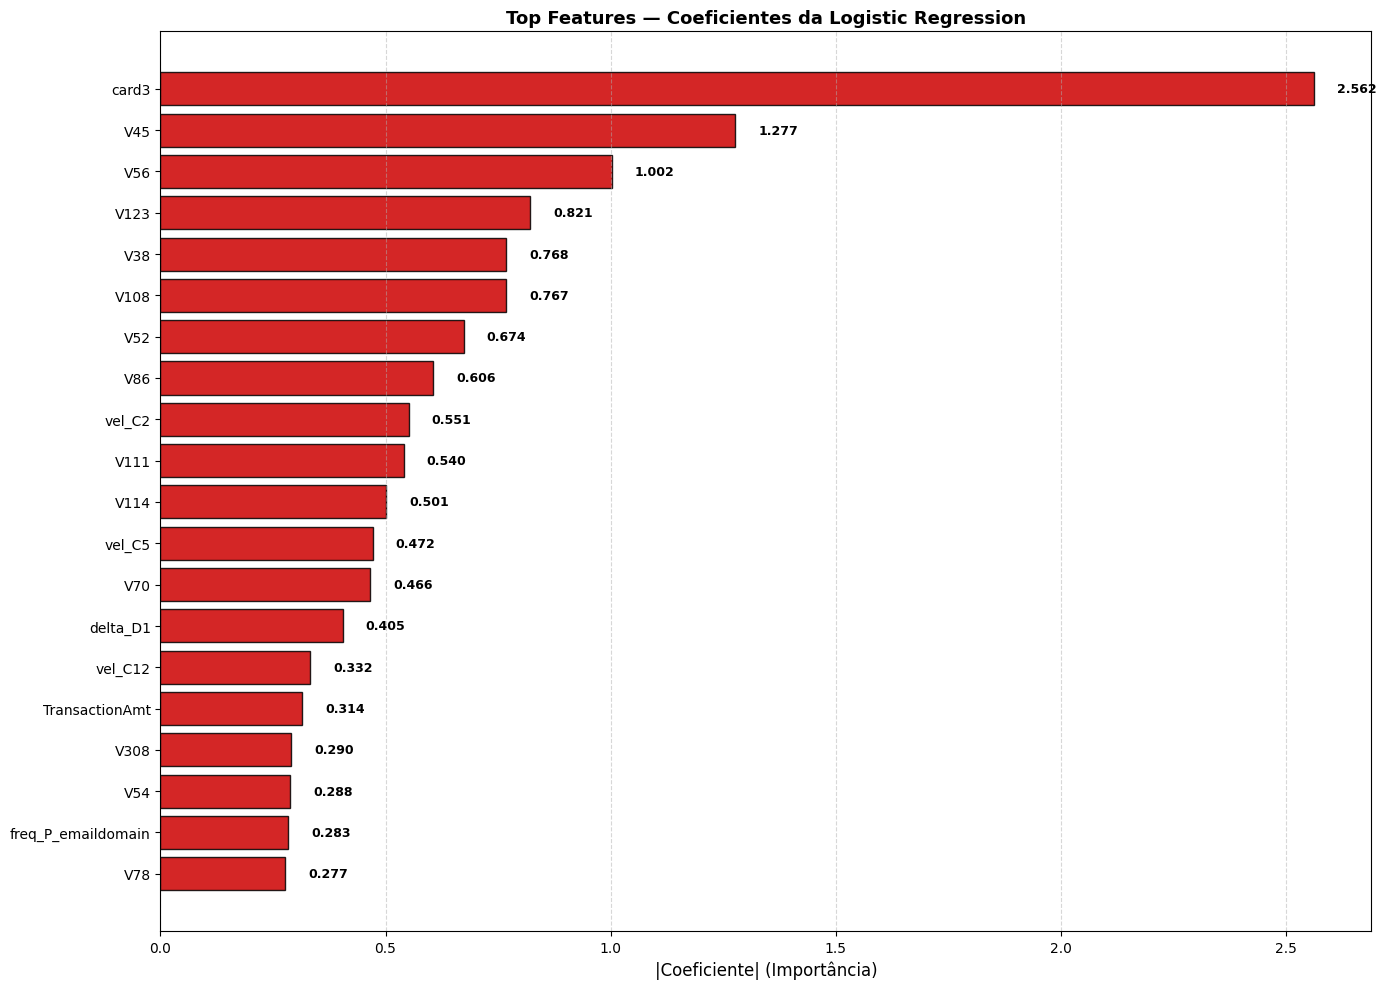

,Feature,Importância
0,card3,2.562047
1,V45,1.276607
2,V56,1.002236
3,V123,0.820885
4,V38,0.768068
5,V108,0.767287
6,V52,0.673757
7,V86,0.606366
8,vel_C2,0.551267
9,V111,0.540268


In [6]:
# ==============================================================================
# 2.2 COEFICIENTES LINEARES DA REGRESSÃO LOGÍSTICA
# ==============================================================================
plot_feature_importance(
    modelo=modelos_ajustados['Logistic_Regression'][-1],
    feature_names=linear_cols,
    top_n=20,
    titulo='Top Features — Coeficientes da Logistic Regression',
    cor="#CD0000",
    xlabel='|Coeficiente| (Importância)',
    figsize=(14, 10),
)


---
## 3.0 Otimização de Hiperparâmetros (Optuna)

Busca Bayesiana de hiperparâmetros com o objetivo de maximizar o ROC-AUC médio na validação cruzada agrupada por mês (`GroupKFold`, CV=3) para os algoritmos de Boosting (LightGBM, XGBoost e CatBoost).

A otimização é conduzida respeitando estritamente a separação temporal dos blocos mensais no treino para evitar vazamento de informação futura.


In [7]:
# ==============================================================================
# 3.0 OTIMIZAÇÃO BAYESIANA (OPTUNA COM GROUPKFOLD POR MÊS) — RUN_OPTUNA = True
# ==============================================================================
if RUN_OPTUNA:
    # 1. Validação Cruzada por Blocos Mensais no Treino (Prevenção estrita de Data Leakage temporal)
    if 'grupos_mes' not in locals():
        grupos_mes = (train_df["TransactionDT"] // (3600 * 24 * 30)).astype(int).values

    cv_tuning = GroupKFold(n_splits=3)

    N_TRIALS = 15
    optuna.logging.set_verbosity(optuna.logging.WARNING)

    print('[1/3] Otimizando LightGBM (GroupKFold por Mês)...')
    study_lgbm = optuna.create_study(direction='maximize')
    study_lgbm.optimize(
        lambda trial: objective_lgbm(
            trial, X_train, y_train, cv_tuning, taxa_desbalanceamento=taxa_desbalanceamento, groups=grupos_mes
        ),
        n_trials=N_TRIALS
    )

    print('[2/3] Otimizando XGBoost (GroupKFold por Mês)...')
    study_xgb = optuna.create_study(direction='maximize')
    study_xgb.optimize(
        lambda trial: objective_xgb(
            trial, X_train, y_train, cv_tuning, taxa_desbalanceamento=taxa_desbalanceamento, groups=grupos_mes
        ),
        n_trials=N_TRIALS
    )

    print('[3/3] Otimizando CatBoost (GroupKFold por Mês)...')
    study_cat = optuna.create_study(direction='maximize')
    study_cat.optimize(
        lambda trial: objective_cat(
            trial, X_train, y_train, cv_tuning, taxa_desbalanceamento=taxa_desbalanceamento, groups=grupos_mes
        ),
        n_trials=N_TRIALS
    )

    print(f'Melhor AUC LGBM : {study_lgbm.best_value:.4f}')
    print(f'Melhor AUC XGB  : {study_xgb.best_value:.4f}')
    print(f'Melhor AUC CAT  : {study_cat.best_value:.4f}')
else:
    print('[INFO] RUN_OPTUNA = False — hiperparâmetros carregados da Seção 4.0 (hardcoded).')


[INFO] RUN_OPTUNA = False — hiperparâmetros carregados da Seção 4.0 (hardcoded).


In [8]:
# ==============================================================================
# 3.1 MELHORES HIPERPARÂMETROS REGISTRADOS DO TUNING
# ==============================================================================
if RUN_OPTUNA:
    print("=== LightGBM ===")
    print(f"Melhor AUC : {study_lgbm.best_value:.4f}")
    print(f"Melhores   : {study_lgbm.best_params}")

    print("\n=== XGBoost ===")
    print(f"Melhor AUC : {study_xgb.best_value:.4f}")
    print(f"Melhores   : {study_xgb.best_params}")

    print("\n=== CatBoost ===")
    print(f"Melhor AUC : {study_cat.best_value:.4f}")
    print(f"Melhores   : {study_cat.best_params}")


---
## 4.0 Hiperparâmetros Campeões (Hardcoded)

Fixação estática das parametrizações ótimas para garantir:
1. Execução determinística e rápida sem necessidade de retreinar Optuna a cada sessão.
2. Rastreabilidade de versionamento para implantação em produção.
3. Reprodutibilidade consistente de experimentos e validação.


In [9]:
# ==============================================================================
# 4.1 HIPERPARÂMETROS CAMPEÕES (OTIMIZADOS VIA OPTUNA)
# ==============================================================================

# LightGBM (Melhor AUC: 0.8988)
best_lgbm_params = {
    'n_estimators': 194,
    'learning_rate': 0.062037961131194,
    'num_leaves': 44,
    'max_depth': 9,
    'subsample': 0.8561325350065099,
    'colsample_bytree': 0.6754897898518821,
    'reg_alpha': 0.013512562153216617,
    'reg_lambda': 1.0035215925696868,
    'scale_pos_weight': taxa_desbalanceamento,
    'random_state': 42,
    'n_jobs': -1,
    'verbosity': -1,
}

# XGBoost (Melhor AUC: 0.8997)
best_xgb_params = {
    'n_estimators': 319,
    'learning_rate': 0.05104647568569471,
    'max_depth': 7,
    'subsample': 0.7090697188454921,
    'colsample_bytree': 0.8323559234248681,
    'reg_alpha': 0.01606824448758865,
    'reg_lambda': 6.471791005948778,
    'scale_pos_weight': taxa_desbalanceamento,
    'eval_metric': 'auc',
    'tree_method': 'hist',
    'random_state': 42,
    'verbosity': 0,
    'n_jobs': -1,
}

# CatBoost (Melhor AUC: 0.8889)
best_cat_params = {
    'iterations': 211,
    'learning_rate': 0.09788196776562404,
    'depth': 8,
    'l2_leaf_reg': 5.866458464189361,
    'scale_pos_weight': taxa_desbalanceamento,
    'eval_metric': 'AUC',
    'random_seed': 42,
    'verbose': False,
    'thread_count': -1,
}

# Se o Optuna foi executado na sessão atual, garante a atualização dinâmica
if RUN_OPTUNA and 'study_lgbm' in locals():
    best_lgbm_params.update(study_lgbm.best_params)
    best_xgb_params.update(study_xgb.best_params)
    best_cat_params.update(study_cat.best_params)

### 4.2 Construção do Dicionário de Modelos Otimizados

Instanciação dos classificadores otimizados conjuntamente com a Regressão Logística para composição da bateria final de validação.


In [10]:
# ==============================================================================
# 4.2 CONSTRUÇÃO DO DICIONÁRIO DE MODELOS OTIMIZADOS
# ==============================================================================
modelos_otimizados = {
    'Logistic_Regression': Pipeline([
        ('select_linear', ColumnTransformer([('num', 'passthrough', linear_cols)], remainder='drop')),
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', RobustScaler()),
        ('model', LogisticRegression(class_weight='balanced', C=0.1, max_iter=1000, random_state=10, n_jobs=-1))
    ]),
    'LightGBM_Opt': LGBMClassifier(**best_lgbm_params),
    'XGBoost_Opt': XGBClassifier(**best_xgb_params),
    'CatBoost_Opt': CatBoostClassifier(**best_cat_params),
}

thresholds_otimizados = {k: 0.5 for k in modelos_otimizados.keys()}

print(f"Modelos configurados: {list(modelos_otimizados.keys())}")


Modelos configurados: ['Logistic_Regression', 'LightGBM_Opt', 'XGBoost_Opt', 'CatBoost_Opt']


---
## 5.0 Avaliação dos Modelos Otimizados (Treino + Teste CV + Validação)

Treinamento dos estimadores otimizados com `GroupKFold` (CV=3) no Treino (`Treino` vs `Teste` no CV) e avaliação no conjunto de **Validação (`df_validacao`)**, preservando o **OOT (`df_oot`)** totalmente cego até a Seção 8.0.


In [11]:
# ==============================================================================
# 5.0 TREINO E AVALIAÇÃO FINAL (GroupKFold CV = 3 | Threshold = 0.5)
# ==============================================================================
resultados_finais = {}

for nome, modelo in modelos_otimizados.items():
    print(f"Treinando e avaliando modelo final: {nome}...")
    resultados_finais[nome] = avaliar_classificador(
        modelo=modelo,
        X_train=X_train,
        y_train=y_train,
        X_test=X_test,
        y_test=y_test,
        nome_modelo=nome,
        cv=3,
        thresholds_dict=thresholds_otimizados,
        groups=grupos_mes
    )


Treinando e avaliando modelo final: Logistic_Regression...
 LOGISTIC_REGRESSION (GroupKFold CV = 3 | Threshold = 0.5000)
------------------------------------------------------------------------------------------------------------
 Taxa Base de Fraude (Target=1): Treino = 3.38% | Teste = 3.90%
------------------------------------------------------------------------------------------------------------

 [ METRICAS INDEPENDENTES DO THRESHOLD (Probabilidades) ]
 Metrica    | Treino     | Teste      | Validacao  | Gap(Va-Tr)  | IC 95% (Teste CV)
------------------------------------------------------------------------------------
 ROC-AUC    | 0.8304     | 0.8061     | 0.8464     | +0.0160     | [0.7755, 0.8367]
 GINI       | 0.6608     | 0.6122     | 0.6928     | +0.0320     | [0.5510, 0.6733]
 PR-AUC     | 0.2618     | 0.2445     | 0.3578     | +0.0960     | -
 KS         | 0.5081     | 0.4734     | 0.5314     | +0.0233     | -

 [ METRICAS DEPENDENTES DO THRESHOLD (Corte = 0.5000) ]
 Metr

### 5.1 Ensemble de Modelos (Postergado para Análise Pós-Execução)

**Pra validar o ensemble, pensamos em analisar a correlação entre os scores calculados (predict_proba)**

- Se os `resultados das correlações de pearson e spearman, forem igualmente próximos de 1`, não faz sentido analisar ensembles, ainda mais que: **Os modelos de boosting analisados apresentaram boa coerência em métricas de avaliação** de modo que:


- **Não faz sentido usar médias ou ranks de modelos que possuem qualidade de predições semelhantes**

In [13]:
# ==============================================================================
# 5.1 ENSEMBLE DE MODELOS — CORRELAÇÃO ENTRE PREDIÇÕES (VALIDAÇÃO)
# ==============================================================================

# 1) Analisando a correlação das probabilidades previstas entre LightGBM e XGBoost em X_test (df_validacao)
y_pred_lgbm = modelos_otimizados['LightGBM_Opt'].predict_proba(X_test)[:, 1]
y_pred_xgb  = modelos_otimizados['XGBoost_Opt'].predict_proba(X_test)[:, 1]

df_correlacao = pd.DataFrame({
    'LightGBM_Opt': y_pred_lgbm,
    'XGBoost_Opt': y_pred_xgb
})

corr_pearson  = df_correlacao['LightGBM_Opt'].corr(df_correlacao['XGBoost_Opt'], method='pearson')
corr_spearman = df_correlacao['LightGBM_Opt'].corr(df_correlacao['XGBoost_Opt'], method='spearman')

print(f"Correlação de Pearson  (LightGBM_Opt vs XGBoost_Opt): {corr_pearson:.4f}")
print(f"Correlação de Spearman (LightGBM_Opt vs XGBoost_Opt): {corr_spearman:.4f}")


Correlação de Pearson  (LightGBM_Opt vs XGBoost_Opt): 0.9524
Correlação de Spearman (LightGBM_Opt vs XGBoost_Opt): 0.9354


---
## 6.0 Calibração de Probabilidades e Análise de Threshold

O ponto de corte (threshold) define o equilíbrio entre Falsos Positivos e Falsos Negativos (trade-off precisão vs. recall) e o impacto financeiro das fraudes não detectadas.
Esta etapa será conduzida manualmente com base na distribuição dos scores e matriz de custo após a primeira execução completa.


In [16]:
# ==============================================================================
# 6.0 CALIBRAÇÃO ISOTÔNICA E OTIMIZAÇÃO DE THRESHOLD FINANCEIRO (LIGHTGBM_OPT)
# ==============================================================================
# 1. Função de Score Financeiro conforme regra de negócio (em US$ reais):
#    VP = Fraude evitada (0 custo direto) | VN = +0.02 * Amt
#    FP = -0.02 * Amt (receita perdida)  | FN = -1.00 * Amt (chargeback)
def calcular_score_financeiro(y_true, y_pred_block, amt, exibir_detalhes=False, titulo=""):
    y_true = np.asarray(y_true)
    amt = np.asarray(amt, dtype=float)
    bloqueado = np.asarray(y_pred_block, dtype=bool)
    aprovado = ~bloqueado

    vp = bloqueado & (y_true == 1)
    vn = aprovado  & (y_true == 0)
    fp = bloqueado & (y_true == 0)
    fn = aprovado  & (y_true == 1)

    qtd_vp, qtd_vn = int(vp.sum()), int(vn.sum())
    qtd_fp, qtd_fn = int(fp.sum()), int(fn.sum())

    vol_vp = float(amt[vp].sum())
    vol_vn = float(amt[vn].sum())
    vol_fp = float(amt[fp].sum())
    vol_fn = float(amt[fn].sum())

    receita_vn  = 0.02 * vol_vn
    penal_fp    = 0.02 * vol_fp
    prejuizo_fn = 1.00 * vol_fn
    perda_total = penal_fp + prejuizo_fn
    resultado_liquido = receita_vn - perda_total

    approval_rate = qtd_vn / max(1, (y_true == 0).sum())
    recall = qtd_vp / max(1, (y_true == 1).sum())
    precision = qtd_vp / max(1, bloqueado.sum())

    resultado = {
        'Resultado_Liquido': resultado_liquido,
        'Receita_VN': receita_vn,
        'Penalidade_FP': penal_fp,
        'Prejuizo_FN': prejuizo_fn,
        'Perda_Total_FP_FN': perda_total,
        'Fraude_Evitada_VP': vol_vp,
        'Volume_VN_USD': vol_vn,
        'Volume_FP_USD': vol_fp,
        'Qtd_VP': qtd_vp,
        'Qtd_VN': qtd_vn,
        'Qtd_FP': qtd_fp,
        'Qtd_FN': qtd_fn,
        'Approval_Rate': approval_rate,
        'Recall': recall,
        'Precision': precision,
    }

    if exibir_detalhes:
        cabecalho = f"DETALHAMENTO FINANCEIRO — {titulo}" if titulo else "DETALHAMENTO FINANCEIRO"
        print("=" * 88)
        print(cabecalho)
        print("-" * 88)
        print(f"[+] GANHO  (VN — Legítimas Aprovadas | +2% MDR): "
              f"{qtd_vn:>7,} tx | Vol: $ {vol_vn:>14,.2f} | Receita: +$ {receita_vn:>12,.2f}")
        print(f"[*] EVITADO (VP — Fraudes Bloqueadas |  0% MDR): "
              f"{qtd_vp:>7,} tx | Fraude Evitada:             $ {vol_vp:>12,.2f}")
        print(f"[-] PERDA FP (Clientes Bons Bloqueados | -2% MDR): "
              f"{qtd_fp:>7,} tx | Vol: $ {vol_fp:>14,.2f} | Perda:   -$ {penal_fp:>12,.2f}")
        print(f"[-] PERDA FN (Fraudes Não Detectadas   | -100%):  "
              f"{qtd_fn:>7,} tx | Chargeback:                 -$ {prejuizo_fn:>12,.2f}")
        print("-" * 88)
        print(f"Perda Total (FP + FN): -$ {perda_total:>12,.2f} | "
              f"RESULTADO LÍQUIDO: $ {resultado_liquido:>14,.2f}")
        print(f"Aprovação (VN): {approval_rate*100:.2f}% | Recall (VP): {recall*100:.2f}% | Precision: {precision*100:.2f}%")
        print("=" * 88)

    return resultado

# 2. Gera predições Out-of-Fold (OOF) temporais no Treino (sem leakage de Validação/OOT)
grupos_mes_cal = (train_df["TransactionDT"] // (3600 * 24 * 30)).astype(int).values
gkf_cal = GroupKFold(n_splits=min(4, len(np.unique(grupos_mes_cal))))

oof_probs_raw = np.zeros(len(X_train))
for tr_idx, va_idx in gkf_cal.split(X_train, y_train, groups=grupos_mes_cal):
    lgb_fold = LGBMClassifier(**best_lgbm_params)
    lgb_fold.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
    oof_probs_raw[va_idx] = lgb_fold.predict_proba(X_train.iloc[va_idx])[:, 1]

# Predição bruta na Validação (X_test = df_validacao) mantendo OOT cego até a Seção 8.0
lgb_full = LGBMClassifier(**best_lgbm_params)
lgb_full.fit(X_train, y_train)
val_probs_raw = lgb_full.predict_proba(X_test)[:, 1]

# 3. Calibração Isotônica (ajustada APENAS no OOF do Treino)
calibrador_iso = IsotonicRegression(out_of_bounds='clip')
oof_probs_cal = calibrador_iso.fit_transform(oof_probs_raw, y_train)
val_probs_cal = calibrador_iso.transform(val_probs_raw)

# 4. Reconversão de TransactionAmt (log1p -> US$ reais) e Varredura de Threshold no Treino
amt_train_real = np.expm1(train_df['TransactionAmt'].values) if train_df['TransactionAmt'].mean() < 10 else train_df['TransactionAmt'].values
amt_val_real   = np.expm1(df_validacao['TransactionAmt'].values) if df_validacao['TransactionAmt'].mean() < 10 else df_validacao['TransactionAmt'].values

grid_thresholds = np.linspace(0.005, 0.30, 300)
resultados_varredura = []

for th in grid_thresholds:
    metricas = calcular_score_financeiro(y_train, oof_probs_cal >= th, amt_train_real)
    metricas['Threshold'] = float(th)
    resultados_varredura.append(metricas)

df_thresholds = pd.DataFrame(resultados_varredura)
melhor_linha_oof = df_thresholds.loc[df_thresholds['Resultado_Liquido'].idxmax()]
threshold_otimo = float(melhor_linha_oof['Threshold'])


OTIMIZAÇÃO FINANCEIRA — LIGHTGBM_OPT (Threshold Ótimo OOF = 0.0366)
Escala TransactionAmt (US$) | Treino: $134.32 média | Validação: $134.63 média

DETALHAMENTO FINANCEIRO — VALIDAÇÃO — CORTE PADRÃO 0.5000 (PROB. BRUTA)
----------------------------------------------------------------------------------------
[+] GANHO  (VN — Legítimas Aprovadas | +2% MDR): 103,416 tx | Vol: $  13,368,323.29 | Receita: +$   267,366.47
[*] EVITADO (VP — Fraudes Bloqueadas |  0% MDR):   3,353 tx | Fraude Evitada:             $   568,838.46
[-] PERDA FP (Clientes Bons Bloqueados | -2% MDR):  10,081 tx | Vol: $   1,736,575.79 | Perda:   -$    34,731.52
[-] PERDA FN (Fraudes Não Detectadas   | -100%):    1,258 tx | Chargeback:                 -$   227,281.42
----------------------------------------------------------------------------------------
Perda Total (FP + FN): -$   262,012.93 | RESULTADO LÍQUIDO: $       5,353.53
Aprovação (VN): 91.12% | Recall (VP): 72.72% | Precision: 24.96%
DETALHAMENTO FINANCEIRO 

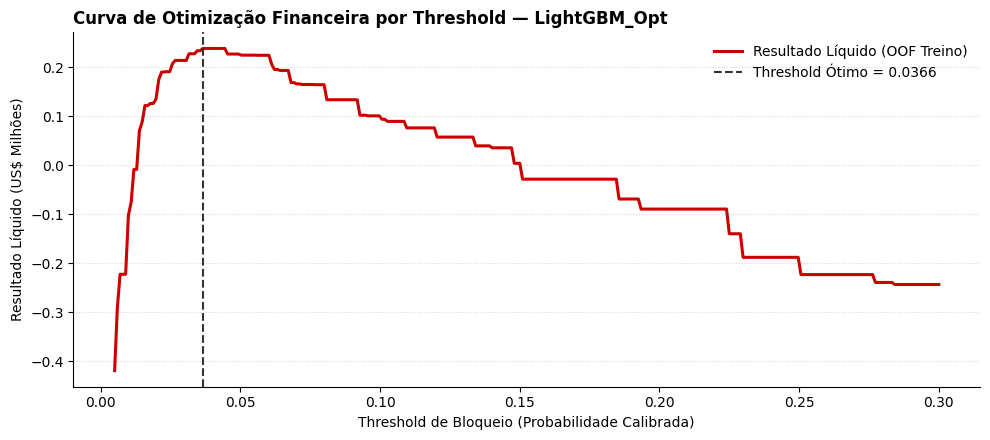

In [17]:
# 5. Avaliação Financeira na Validação (df_validacao) usando o threshold_otimo congelado
print(f"OTIMIZAÇÃO FINANCEIRA — LIGHTGBM_OPT (Threshold Ótimo OOF = {threshold_otimo:.4f})")
print(f"Escala TransactionAmt (US$) | Treino: ${amt_train_real.mean():,.2f} média | Validação: ${amt_val_real.mean():,.2f} média\n")

res_val_padrao = calcular_score_financeiro(
    y_test, val_probs_raw >= 0.50, amt_val_real,
    exibir_detalhes=True, titulo="VALIDAÇÃO — CORTE PADRÃO 0.5000 (PROB. BRUTA)"
)
res_val_otimo = calcular_score_financeiro(
    y_test, val_probs_cal >= threshold_otimo, amt_val_real,
    exibir_detalhes=True, titulo=f"VALIDAÇÃO — CORTE ÓTIMO {threshold_otimo:.4f} (PROB. CALIBRADA)"
)

delta_vn     = res_val_otimo['Receita_VN']        - res_val_padrao['Receita_VN']
delta_fp     = res_val_otimo['Penalidade_FP']     - res_val_padrao['Penalidade_FP']
delta_fn     = res_val_otimo['Prejuizo_FN']       - res_val_padrao['Prejuizo_FN']
delta_vp     = res_val_otimo['Fraude_Evitada_VP'] - res_val_padrao['Fraude_Evitada_VP']
delta_liq    = res_val_otimo['Resultado_Liquido'] - res_val_padrao['Resultado_Liquido']

print("COMPARATIVO ÓTIMO vs. PADRÃO 0.50 (VALIDAÇÃO)")
print("-" * 88)
print(f"  Δ Receita VN (Aprovação Legítima): {delta_vn:+14,.2f} US$")
print(f"  Δ Perda FP   (Falso Positivo)    : {delta_fp:+14,.2f} US$")
print(f"  Δ Perda FN   (Falso Negativo)    : {delta_fn:+14,.2f} US$")
print(f"  Δ Fraude Evitada (VP)            : {delta_vp:+14,.2f} US$")
print(f"  Δ GANHO FINANCEIRO LÍQUIDO       : {delta_liq:+14,.2f} US$")
print("=" * 88)

# 6. Curva de Trade-off Financeiro (Treino OOF em US$ reais)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(df_thresholds['Threshold'], df_thresholds['Resultado_Liquido'] / 1e6, color='#CD0000', lw=2.2, label='Resultado Líquido (OOF Treino)')
ax.axvline(threshold_otimo, color='#333333', linestyle='--', lw=1.5, label=f'Threshold Ótimo = {threshold_otimo:.4f}')
ax.set_title('Curva de Otimização Financeira por Threshold — LightGBM_Opt', fontsize=12, fontweight='bold', loc='left')
ax.set_xlabel('Threshold de Bloqueio (Probabilidade Calibrada)')
ax.set_ylabel('Resultado Líquido (US$ Milhões)')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', linestyle=':', alpha=0.5)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()


---
## 7.0 Análise SHAP e Redução Dimensional (Modelo LITE)

- Avaliação da contribuição marginal global de cada variável utilizando feature importance por splits e SHAP values via `TreeExplainer`.
- Identificação de features com menor impacto discriminatório para simplificação da esteira produtiva.
- Treinamento comparativo de uma versão LITE sem as features fracas, validando que a perda de ROC-AUC seja desprezível (Δ ≤ −0.0010).


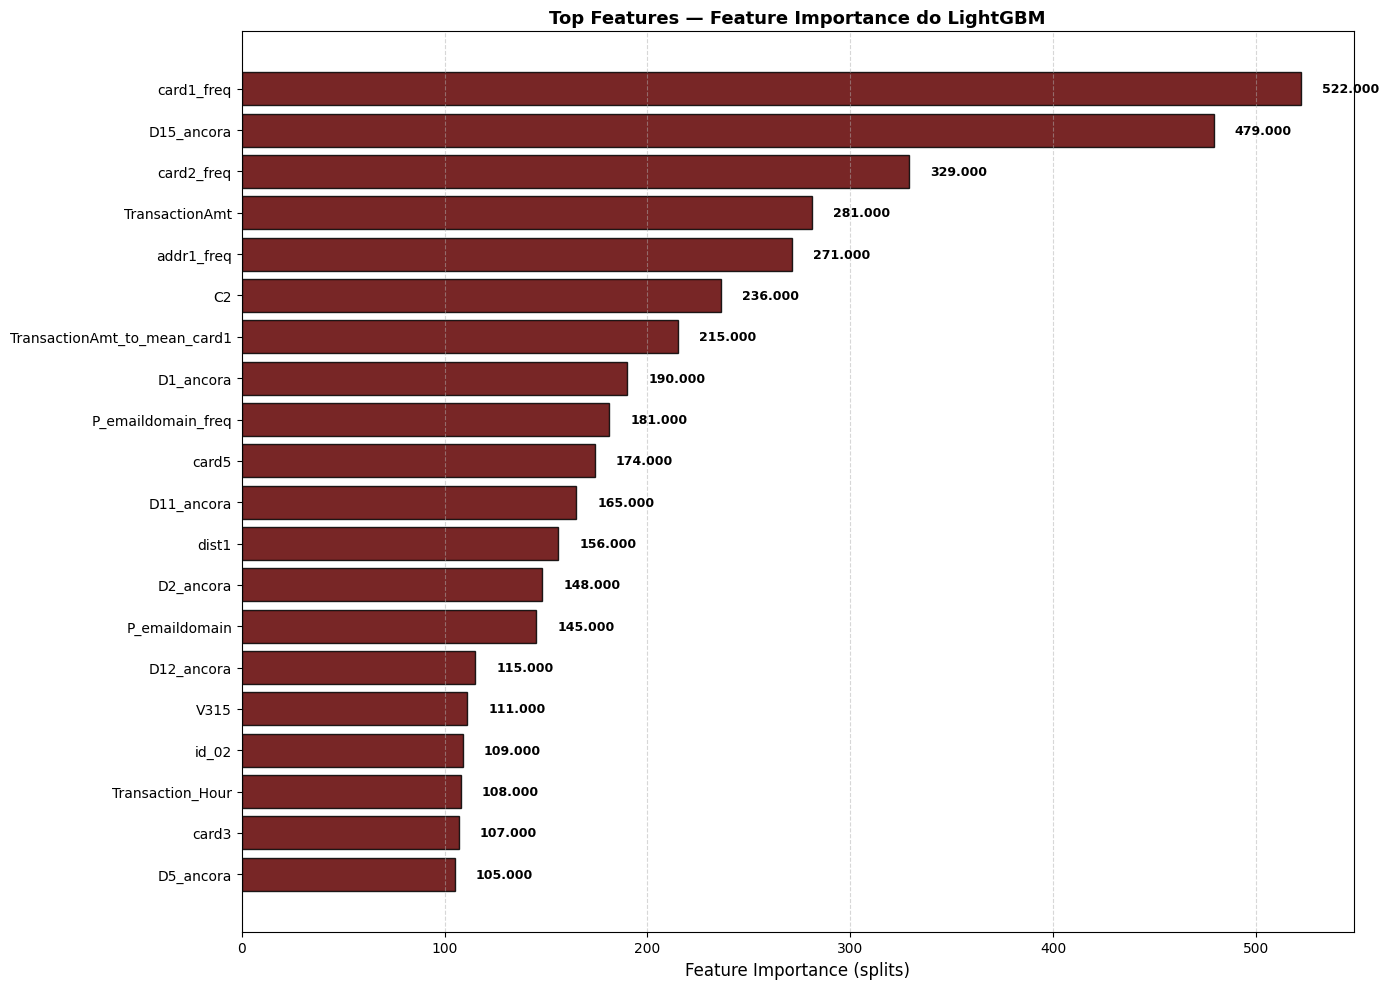

,Feature,Importância
0,card1_freq,522
1,D15_ancora,479
2,card2_freq,329
3,TransactionAmt,281
4,addr1_freq,271
5,C2,236
6,TransactionAmt_to_mean_card1,215
7,D1_ancora,190
8,P_emaildomain_freq,181
9,card5,174


: 

: 

In [ ]:
# ==============================================================================
# 7.1 FEATURE IMPORTANCE DO LIGHTGBM OTIMIZADO
# ==============================================================================
plot_feature_importance(
    modelo=modelos_otimizados['LightGBM_Opt'],
    feature_names=X_train.columns,
    top_n=20,
    titulo='Top Features — Feature Importance do LightGBM',
    cor="#610000",
    xlabel='Feature Importance (splits)',
    figsize=(14, 10),
)




### 7.2 Features de Menor Impacto SHAP 

Identificação das variáveis com menor média de impacto absoluto $|\text{SHAP}|$ em uma amostra representativa do treino.


In [ ]:
# ==============================================================================
# 7.2 FEATURES DE MENOR IMPACTO POR |SHAP| — executa se RUN_SHAP_PRUNING = True
# ==============================================================================
if RUN_SHAP_PRUNING:
    # Amostra extraída estritamente do Treino para evitar vazamento futuro
    X_amostra_shap = X_train.sample(n=min(15000, len(X_train)), random_state=10)
    df_menores_shap = obter_menores_features(
        modelo=modelos_otimizados['LightGBM_Opt'],
        X_amostra=X_amostra_shap,
        bottom_n=20,
        exibir=True,
    )
else:
    print("[INFO] RUN_SHAP_PRUNING = False")


,Feature,fraqueza
0,V1,0.000000
1,V65,0.000000
2,V68,0.000000
3,V114,0.000000
4,V117,0.000000
5,V111,0.000000
6,id_12_num,0.000000
7,V240,0.000000
8,M1_num,0.000000
9,device_ip_consistency,0.000000


: 

: 

### 7.3 Poda de Features e Sanity Check (Modelo LITE)

Treinamento comparativo da arquitetura sem as variáveis de menor impacto para avaliar se a perda de ROC-AUC no conjunto de **Validação (`df_validacao` / `X_test`)** respeita o limiar de tolerância estatística.


In [ ]:
# ==============================================================================
# 7.3 SHAP + RE-TREINO LITE — executa apenas se RUN_SHAP_PRUNING = True
# ==============================================================================
if RUN_SHAP_PRUNING:
    if 'X_amostra_shap' not in locals():
        X_amostra_shap = X_train.sample(n=min(15000, len(X_train)), random_state=10)
    cortes = podar_features_por_shap(
        {'LightGBM_Opt': modelos_otimizados['LightGBM_Opt']},
        X_train, y_train, X_test, y_test, X_amostra_shap,
        top_n_remover=10
    )
else:
    print('[INFO] RUN_SHAP_PRUNING = False — listas de poda carregadas da Seção 7.4 (hardcoded).')

# Fazer um gráfico disso, sem duvida


 ANALISE SHAP E SANITY CHECK DE PODA: LightGBM_Opt 
As 10 features menos relevantes:
  - V1
  - V65
  - V68
  - V114
  - V117
  - V111
  - id_12_num
  - V240
  - M1_num
  - device_ip_consistency

Treinando arquitetura LITE sem 10 features...
  ROC-AUC Original : 0.9068
  ROC-AUC Lite     : 0.9069
  Delta (AUC)      : +0.0001

  [VEREDITO] Valido! Modelo mais limpo e rapido sem perda significativa.


: 

: 

### 7.4 Registro das Features Sugeridas para Poda

Declaração da lista de variáveis descartáveis para parametrização direta do modelo enxuto.


In [ ]:
# ==============================================================================
# 7.4 FEATURES SUGERIDAS PARA CORTE (RESULTADO DA SEÇÃO 7.3)
# ==============================================================================
FEATURES_PODA_SHAP = {
    'LightGBM_Opt': cortes.get('LightGBM_Opt', []) if ('cortes' in locals() and isinstance(cortes, dict)) else []
}


: 

: 

---
## 8.0 Avaliação Final no OOT (Cega) e Exportação dos Artefatos

Avaliação única e cega do modelo campeão na base **Out-of-Time (`df_oot`, últimos 20%)** via `avaliar_classificacao_oot` comparando com a base de Validação (`df_validacao`), seguida da exportação para `/artifacts`:
- `modelo_fraude.joblib`: Estimador serializado para inferência.
- `modelo_fraude_metadata.json`: Especificação de features e dimensões de Treino, Validação e OOT.
- `modelo_fraude_metrics.json`: Métricas consolidadas de Treino, Validação e OOT.

In [ ]:
# ==============================================================================
# 8.0 AVALIAÇÃO FINAL CEGA NO OOT E EXPORTAÇÃO DO MODELO CAMPEÃO
# ==============================================================================
caminho_artifacts = PROJECT_ROOT / 'artifacts'
caminho_artifacts.mkdir(parents=True, exist_ok=True)

# 1. Definição das features finais
features_remover = FEATURES_PODA_SHAP.get('LightGBM_Opt', [])
features_finais = [c for c in features_cols if c not in features_remover]

print(f"[INFO] Features originais : {len(features_cols)}")
print(f"[INFO] Features removidas : {len(features_remover)}")
print(f"[INFO] Features finais    : {len(features_finais)}")

X_train_final = X_train[features_finais]
X_test_final  = X_test[features_finais]
X_oot_final   = X_oot[features_finais]

# 2. Treino do Modelo Campeão no Treino (60%)
print(f"\n[INFO] Treinando modelo campeão final ({len(features_finais)} features)...")
modelo_campeao = LGBMClassifier(**best_lgbm_params)
modelo_campeao.fit(X_train_final, y_train)

# 3. Avaliação Final Única no OOT (20% finais — nunca vistos antes)
prob_oot_final, pred_oot_final = avaliar_classificacao_oot(
    modelo=modelo_campeao,
    X_oot=X_oot_final,
    y_oot=y_oot,
    X_hist=X_test_final,
    y_hist=y_test,
    threshold=threshold_otimo,
    nome_modelo=''
)

# 4. Exportação dos artefatos oficiais (incluindo métricas do OOT)
print("\n" + "=" * 80)
exportar_artefatos_modelo(
    nome_modelo='modelo_fraude',
    modelo=modelo_campeao,
    diretorio_destino=caminho_artifacts,
    threshold_otimo=threshold_otimo,
    features_utilizadas=features_finais,
    X_train=X_train_final,
    y_train=y_train,
    X_test=X_test_final,
    y_test=y_test,
    X_oot=X_oot_final,
    y_oot=y_oot
)
print("=" * 80)


: 

: 